In [12]:
import sys
import os

print("Python executable:", sys.executable)
print("Python version:   ", sys.version.split()[0])
print("Virtual env:      ", os.environ.get("VIRTUAL_ENV", "❌ NONE (not a venv!)"))
print("Kernel name:      ", os.environ.get("JPY_PARENT_PYTHON", "n/a"))

Python executable: c:\Users\ycode\Desktop\2nd_YouCode\briefs\Classification_images_Deep_Learning\venv\Scripts\python.exe
Python version:    3.12.10
Virtual env:       C:\Users\ycode\Desktop\2nd_YouCode\briefs\Classification_images_Deep_Learning\venv
Kernel name:       n/a


# 01 — Exploration du dataset Intel Image Classification

**Objectif :** comprendre la structure du dataset, identifier les classes,
vérifier la distribution, visualiser des exemples, et préparer la stratégie
de split (train / val / test) stratifiée.

In [13]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter

# Make src/ importable
sys.path.append(os.path.abspath(".."))

from src.data import (
    collect_paths_and_labels,
    stratified_split,
    IMG_SIZE,
    SEED,
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

## 1. Chargement des chemins et labels

On parcourt le dossier `seg_train` (le seul dossier labellisé).
Chaque sous-dossier = une classe.

In [14]:
DATA_DIR = "../Intel_Image_Classification/seg_train_test/seg_train"

paths, labels, class_names = collect_paths_and_labels(DATA_DIR)

print("Total images :", len(paths))
print("Classes      :", class_names)
print("Label range  :", labels.min(), "→", labels.max())

Total images : 17034
Classes      : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Label range  : 0 → 5


## 2. Distribution des classes

In [15]:
counts = Counter(labels)
df_counts = pd.DataFrame({
    "class": class_names,
    "count": [counts[i] for i in range(len(class_names))],
})
df_counts["pct"] = (df_counts["count"] / df_counts["count"].sum() * 100).round(2)
df_counts

,class,count,pct
0,buildings,2628,15.43
1,forest,2745,16.11
2,glacier,2957,17.36
3,mountain,3037,17.83
4,sea,2784,16.34
5,street,2883,16.92


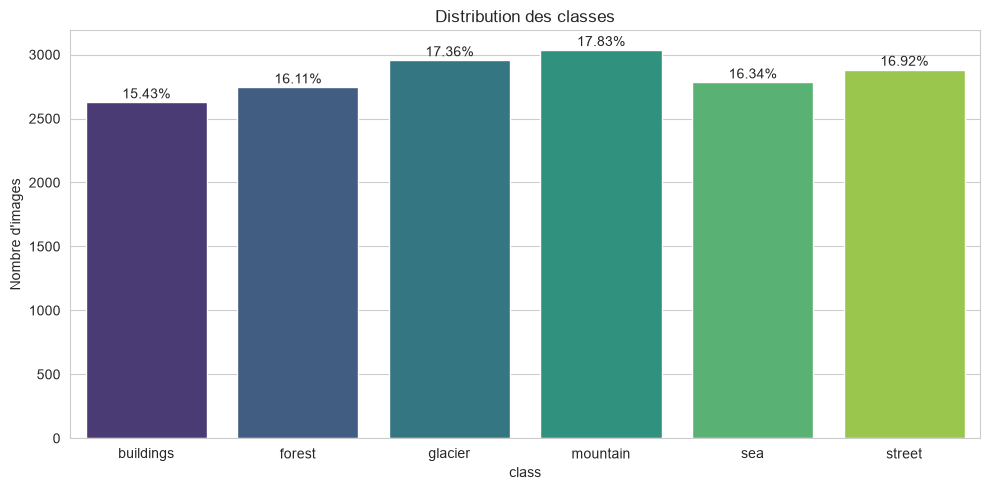

In [20]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df_counts, x="class", y="count", hue="class", palette="viridis", legend=False)
plt.title("Distribution des classes")
plt.ylabel("Nombre d'images")
for i, row in df_counts.iterrows():
    plt.text(i, row["count"] + 30, f'{row["pct"]}%', ha="center")
plt.tight_layout()
plt.show()

## 3. Visualisation d'exemples par classe

On affiche 3 images aléatoires par classe pour vérifier
visuellement la cohérence entre l'image et son label.

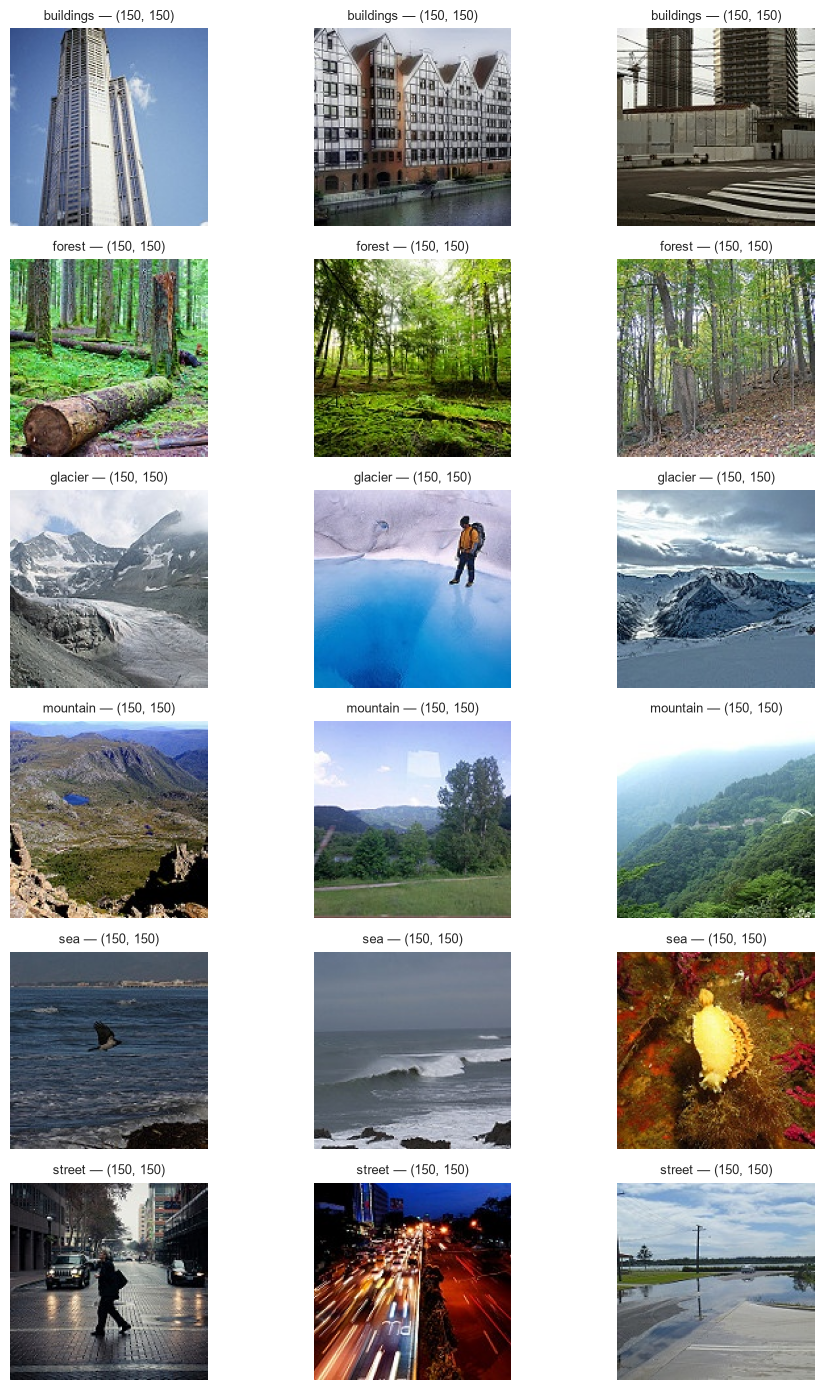

In [ ]:
import random

random.seed("40")

fig, axes = plt.subplots(len(class_names), 3, figsize=(10, 14))

for row, cls_idx in enumerate(range(len(class_names))):
    cls_paths = [p for p, l in zip(paths, labels) if l == cls_idx]
    samples = random.sample(cls_paths, 3)
    for col, p in enumerate(samples):
        img = Image.open(p)
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
        axes[row, col].set_title(
            f"{class_names[cls_idx]} — {img.size}", fontsize=9
        )

plt.tight_layout()
plt.show()